# Phase 3A Step 7 — Comprehensive Univariate Analysis

## Customer Retention Intelligence System

This independent notebook profiles each predictor in the IBM Telco development split
without using the target. It focuses on distribution shape, concentration, category
structure, rarity, variability, and Shannon entropy.

### Scope boundaries

- The configured `data/processed/development.parquet` file is the only dataset loaded.
- `customerID` is treated as an identifier and `Churn` is excluded from predictor
  analysis.
- No feature-target, bivariate, multivariate, inferential, feature-selection,
  transformation, encoding, balancing, or modelling operation is performed.
- Visual and numerical patterns are descriptive. A feature's marginal distribution does
  not establish any relationship with churn or any causal business effect.

The preceding EDA notebook is not required to run this notebook. Selected visualization
types reappear because this artifact must be independently executable, but the analysis
emphasizes new Step 7 questions: boundary concentration, possible multimodality, rare and
dominant categories, low variability, and entropy.

## 1. Environment, configuration, and leakage-safe data loading

The project root is discovered by walking upward until both `pyproject.toml` and
`params.yaml` are found. The existing `retention.utils.config.load_config` utility supplies
the data path and project settings. The resolved path is asserted to be the development
artifact before reading it.

This design avoids dependence on the notebook launch directory and prevents accidental
analysis of a held-out or pre-split dataset.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Find the nearest parent containing the project marker files.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "params.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
expected_development_path = Path("data/processed/development.parquet")
assert configured_development_path == expected_development_path

development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file(), f"Missing development data: {development_path}"

required_packages = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "pyarrow"]
environment = {
    "Python": sys.version.split()[0],
    "Executable": sys.executable,
    **{package: metadata.version(package) for package in required_packages},
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Configured input: {configured_development_path}")
print(f"Python 3.11 kernel: {sys.version_info[:2] == (3, 11)}")
for name, value in environment.items():
    print(f"{name}: {value}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Configured input: data/processed/development.parquet
Python 3.11 kernel: True
Python: 3.11.14
Executable: /Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.17.1
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy.signal import find_peaks
from scipy.stats import entropy as shannon_entropy
from scipy.stats import gaussian_kde

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

df = pd.read_parquet(development_path)
print(f"Loaded development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded development data: 5,634 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100,"5,475.900",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350,212.300,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450,137.100,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750,"2,453.300",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000,"1,164.050",No


## 2. Predictor roles and independent feature definitions

Storage type and statistical role are different. `SeniorCitizen` is integer-coded but
represents two labels, so it is a binary categorical predictor. `tenure` is a discrete
quantitative count of completed months. The two charge variables are treated as continuous
quantitative measurements.

`customerID` is excluded because it identifies a customer rather than measuring a reusable
predictor. `Churn` is excluded because Step 7 is predictor-only univariate analysis.

In [3]:
# ruff: noqa: E501
identifier_column = config["data"]["id_column"]
target_column = config["data"]["target_column"]

discrete_numerical_features = ["tenure"]
continuous_numerical_features = ["MonthlyCharges", "TotalCharges"]
numerical_features = discrete_numerical_features + continuous_numerical_features

binary_categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
]
ordinal_categorical_features = ["Contract"]
nominal_categorical_features = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaymentMethod",
]
categorical_features = (
    binary_categorical_features
    + ordinal_categorical_features
    + nominal_categorical_features
)

predictor_columns = numerical_features + categorical_features
expected_columns = set(predictor_columns + [identifier_column, target_column])
assert expected_columns == set(df.columns)
assert "SeniorCitizen" in categorical_features
assert "SeniorCitizen" not in numerical_features
assert target_column not in predictor_columns
assert identifier_column not in predictor_columns

feature_role_summary = pd.DataFrame({
    "feature": predictor_columns,
    "role": (
        ["Discrete quantitative"]
        + ["Continuous quantitative"] * 2
        + ["Binary categorical"] * len(binary_categorical_features)
        + ["Ordinal categorical"] * len(ordinal_categorical_features)
        + ["Nominal categorical"] * len(nominal_categorical_features)
    ),
    "storage_dtype": [str(df[column].dtype) for column in predictor_columns],
})
display(feature_role_summary)

,feature,role,storage_dtype
0,tenure,Discrete quantitative,int64
1,MonthlyCharges,Continuous quantitative,float64
2,TotalCharges,Continuous quantitative,float64
3,gender,Binary categorical,string
4,SeniorCitizen,Binary categorical,int64
5,Partner,Binary categorical,string
6,Dependents,Binary categorical,string
7,PhoneService,Binary categorical,string
8,PaperlessBilling,Binary categorical,string
9,Contract,Ordinal categorical,string


# 3. Numerical feature profiling

## 3.1 Focused distribution statistics

This notebook does not repeat the complete central-tendency and dispersion tables from
Step 5. Instead, it calculates a focused profile needed for univariate diagnostics:

- adjusted skewness for asymmetry;
- Fisher excess kurtosis for tail/peakedness comparison with a normal reference;
- coefficient of variation $CV=s/\bar{x}$ for relative dispersion;
- zero, minimum, maximum, and most-common exact-value concentrations;
- selected quantiles and IQR for robust position and spread.

Skewness and excess kurtosis are moment summaries, not normality tests. A positive skew
indicates a longer right tail; a negative skew indicates a longer left tail. Positive
excess kurtosis indicates heavier tails than a normal reference, while negative values
indicate a flatter/lighter-tailed shape. These measures are sensitive to unusual values
and do not uniquely determine distribution shape.

For a positive ratio-scale variable,

$$CV=\frac{s}{\bar{x}}\times100\%.$$

CV comparisons are descriptive and become unstable when the mean approaches zero.

In [4]:
# ruff: noqa: E501
numerical_profile_rows = []
for column in numerical_features:
    series = df[column]
    counts = series.value_counts(dropna=False)
    quantiles = series.quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    numerical_profile_rows.append({
        "feature": column,
        "statistical_type": (
            "Discrete quantitative"
            if column in discrete_numerical_features
            else "Continuous quantitative"
        ),
        "skewness": series.skew(),
        "excess_kurtosis": series.kurt(),
        "coefficient_of_variation_percent": series.std(ddof=1) / series.mean() * 100,
        "zero_count": int(series.eq(0).sum()),
        "zero_percentage": series.eq(0).mean() * 100,
        "minimum": series.min(),
        "minimum_count": int(series.eq(series.min()).sum()),
        "minimum_percentage": series.eq(series.min()).mean() * 100,
        "maximum": series.max(),
        "maximum_count": int(series.eq(series.max()).sum()),
        "maximum_percentage": series.eq(series.max()).mean() * 100,
        "most_common_exact_value": counts.index[0],
        "most_common_exact_count": int(counts.iloc[0]),
        "most_common_exact_percentage": counts.iloc[0] / len(series) * 100,
        "p01": quantiles.loc[0.01],
        "p05": quantiles.loc[0.05],
        "p10": quantiles.loc[0.10],
        "p25": quantiles.loc[0.25],
        "p50": quantiles.loc[0.50],
        "p75": quantiles.loc[0.75],
        "p90": quantiles.loc[0.90],
        "p95": quantiles.loc[0.95],
        "p99": quantiles.loc[0.99],
        "IQR": quantiles.loc[0.75] - quantiles.loc[0.25],
    })

numerical_profile = pd.DataFrame(numerical_profile_rows).set_index("feature")
display(numerical_profile)

,statistical_type,skewness,excess_kurtosis,coefficient_of_variation_percent,zero_count,zero_percentage,minimum,minimum_count,minimum_percentage,maximum,maximum_count,maximum_percentage,most_common_exact_value,most_common_exact_count,most_common_exact_percentage,p01,p05,p10,p25,p50,p75,p90,p95,p99,IQR
feature,,,,,,,,,,,,,,,,,,,,,,,,,
tenure,Discrete quantitative,0.241,-1.387,75.990,10,0.177,0.000,10,0.177,72.000,299,5.307,1.000,497,8.821,1.000,1.000,2.000,9.000,29.000,55.000,69.000,72.000,72.000,46.000
MonthlyCharges,Continuous quantitative,-0.235,-1.240,46.166,0,0.000,18.400,1,0.018,118.750,1,0.018,20.050,48,0.852,19.200,19.650,20.050,38.312,70.525,89.900,102.585,107.567,114.984,51.588
TotalCharges,Continuous quantitative,0.962,-0.227,99.377,10,0.177,0.000,10,0.177,"8,684.800",1,0.018,0.000,10,0.177,19.750,48.698,80.880,393.225,"1,395.525","3,832.900","6,000.025","6,975.775","8,064.280","3,439.675"


In [5]:
# ruff: noqa: E501
display(Markdown(
    "\n".join([
        "### Observed numerical findings",
        "",
        f"- **Tenure:** skewness {numerical_profile.loc['tenure', 'skewness']:.3f} is mild and positive, "
        f"while excess kurtosis {numerical_profile.loc['tenure', 'excess_kurtosis']:.3f} indicates a "
        f"flat, non-normal shape. The modal exact value is 1 month "
        f"({numerical_profile.loc['tenure', 'most_common_exact_percentage']:.2f}%). The 72-month maximum "
        f"contains {numerical_profile.loc['tenure', 'maximum_percentage']:.2f}% of customers, and p95=p99=72, "
        "showing an upper-bound ceiling concentration. Only 10 customers have zero tenure; the strong "
        "near-floor concentration is at 1 month rather than exactly zero.",
        f"- **Monthly charges:** skewness {numerical_profile.loc['MonthlyCharges', 'skewness']:.3f} is mild "
        f"and negative, with CV {numerical_profile.loc['MonthlyCharges', 'coefficient_of_variation_percent']:.1f}%. "
        f"The lower 10% lie at or below {numerical_profile.loc['MonthlyCharges', 'p10']:.2f}, close to the "
        f"{numerical_profile.loc['MonthlyCharges', 'minimum']:.2f} floor. Exact minimum and maximum values "
        "each occur once, so there is no exact boundary pile-up.",
        f"- **Total charges:** skewness {numerical_profile.loc['TotalCharges', 'skewness']:.3f} confirms a "
        f"long right tail, and CV {numerical_profile.loc['TotalCharges', 'coefficient_of_variation_percent']:.1f}% "
        "shows extremely high relative dispersion. Ten zero values align with the known zero-tenure accounts. "
        f"The median is {numerical_profile.loc['TotalCharges', 'p50']:.2f}, while p90 reaches "
        f"{numerical_profile.loc['TotalCharges', 'p90']:.2f}; accumulated expenditure is widely dispersed.",
    ])
))

### Observed numerical findings

- **Tenure:** skewness 0.241 is mild and positive, while excess kurtosis -1.387 indicates a flat, non-normal shape. The modal exact value is 1 month (8.82%). The 72-month maximum contains 5.31% of customers, and p95=p99=72, showing an upper-bound ceiling concentration. Only 10 customers have zero tenure; the strong near-floor concentration is at 1 month rather than exactly zero.
- **Monthly charges:** skewness -0.235 is mild and negative, with CV 46.2%. The lower 10% lie at or below 20.05, close to the 18.40 floor. Exact minimum and maximum values each occur once, so there is no exact boundary pile-up.
- **Total charges:** skewness 0.962 confirms a long right tail, and CV 99.4% shows extremely high relative dispersion. Ten zero values align with the known zero-tenure accounts. The median is 1395.53, while p90 reaches 6000.03; accumulated expenditure is widely dispersed.

## 3.2 Exploratory multimodality and concentration

A **mode** is a local or global concentration, but “number of modes” is not an invariant
fact for continuous sample data. Histogram bins and KDE bandwidth can create, merge, or
hide peaks. For the continuous variables, the code evaluates a Gaussian KDE on a grid and
uses a prominence threshold equal to 5% of the maximum density. The detected peaks are
exploratory visual aids—not formal evidence of a mixture distribution.

Tenure is discrete, bounded, and strongly concentrated near its endpoints. Applying a KDE
would imply fractional months and can leak density beyond 0–72, so its leading exact
frequencies are examined instead.

Business relevance: multiple price concentrations may reflect service bundles or plan
tiers, while tenure boundary concentrations may reflect newly acquired and long-observed
customers. Those explanations remain hypotheses until later analyses examine plan and
service variables jointly.

In [6]:
# ruff: noqa: E501
kde_peak_rows = []
for column in continuous_numerical_features:
    series = df[column].to_numpy()
    grid = np.linspace(series.min(), series.max(), 1_000)
    density = gaussian_kde(series)(grid)
    peak_indices, properties = find_peaks(
        density,
        prominence=0.05 * density.max(),
        distance=30,
    )
    for peak_index, prominence in zip(
        peak_indices,
        properties["prominences"],
        strict=True,
    ):
        kde_peak_rows.append({
            "feature": column,
            "exploratory_peak_location": grid[peak_index],
            "density_at_peak": density[peak_index],
            "peak_prominence": prominence,
        })

kde_peak_summary = pd.DataFrame(kde_peak_rows)
tenure_top_frequencies = (
    df["tenure"]
    .value_counts()
    .head(10)
    .rename_axis("tenure_months")
    .rename("count")
    .to_frame()
)
tenure_top_frequencies["percentage"] = tenure_top_frequencies["count"] / len(df) * 100

display(Markdown("**Exploratory continuous KDE peaks**"))
display(kde_peak_summary)
display(Markdown("**Ten leading exact tenure frequencies**"))
display(tenure_top_frequencies)
display(Markdown(
    "**Interpretation:** the selected KDE rule finds two monthly-charge peaks near "
    f"{kde_peak_summary.loc[kde_peak_summary['feature'].eq('MonthlyCharges'), 'exploratory_peak_location'].iloc[0]:.1f} "
    "and "
    f"{kde_peak_summary.loc[kde_peak_summary['feature'].eq('MonthlyCharges'), 'exploratory_peak_location'].iloc[1]:.1f}, "
    "so a possible bimodal/multimodal price structure merits later plan-level investigation. "
    "Total charges show one broad low-value KDE peak plus a long right tail under this bandwidth. "
    "Tenure's two most prominent exact concentrations are 1 and 72 months, suggesting endpoint/lifecycle "
    "concentration rather than a simple bell-shaped population."
))

**Exploratory continuous KDE peaks**

,feature,exploratory_peak_location,density_at_peak,peak_prominence
0,MonthlyCharges,21.213,0.016,0.002
1,MonthlyCharges,80.579,0.013,0.010
2,TotalCharges,347.740,0.000,0.000


**Ten leading exact tenure frequencies**

,count,percentage
tenure_months,,
1,497,8.821
72,299,5.307
2,192,3.408
3,161,2.858
4,141,2.503
71,133,2.361
7,103,1.828
12,98,1.739
9,98,1.739


**Interpretation:** the selected KDE rule finds two monthly-charge peaks near 21.2 and 80.6, so a possible bimodal/multimodal price structure merits later plan-level investigation. Total charges show one broad low-value KDE peak plus a long right tail under this bandwidth. Tenure's two most prominent exact concentrations are 1 and 72 months, suggesting endpoint/lifecycle concentration rather than a simple bell-shaped population.

# 4. Numerical visualizations

## 4.1 Histograms and KDE

A histogram estimates distribution shape through bin counts. It preserves counts but its
appearance depends on bin boundaries and widths. A KDE estimates a smooth density,

$$\widehat f_h(x)=\frac{1}{nh}\sum_{i=1}^{n}
K\left(\frac{x-x_i}{h}\right),$$

where bandwidth $h$ controls smoothing. KDE is shown only for the continuous charge
variables. It can obscure discrete spikes, suggest density outside valid bounds, and make
multimodality appear or disappear as bandwidth changes.

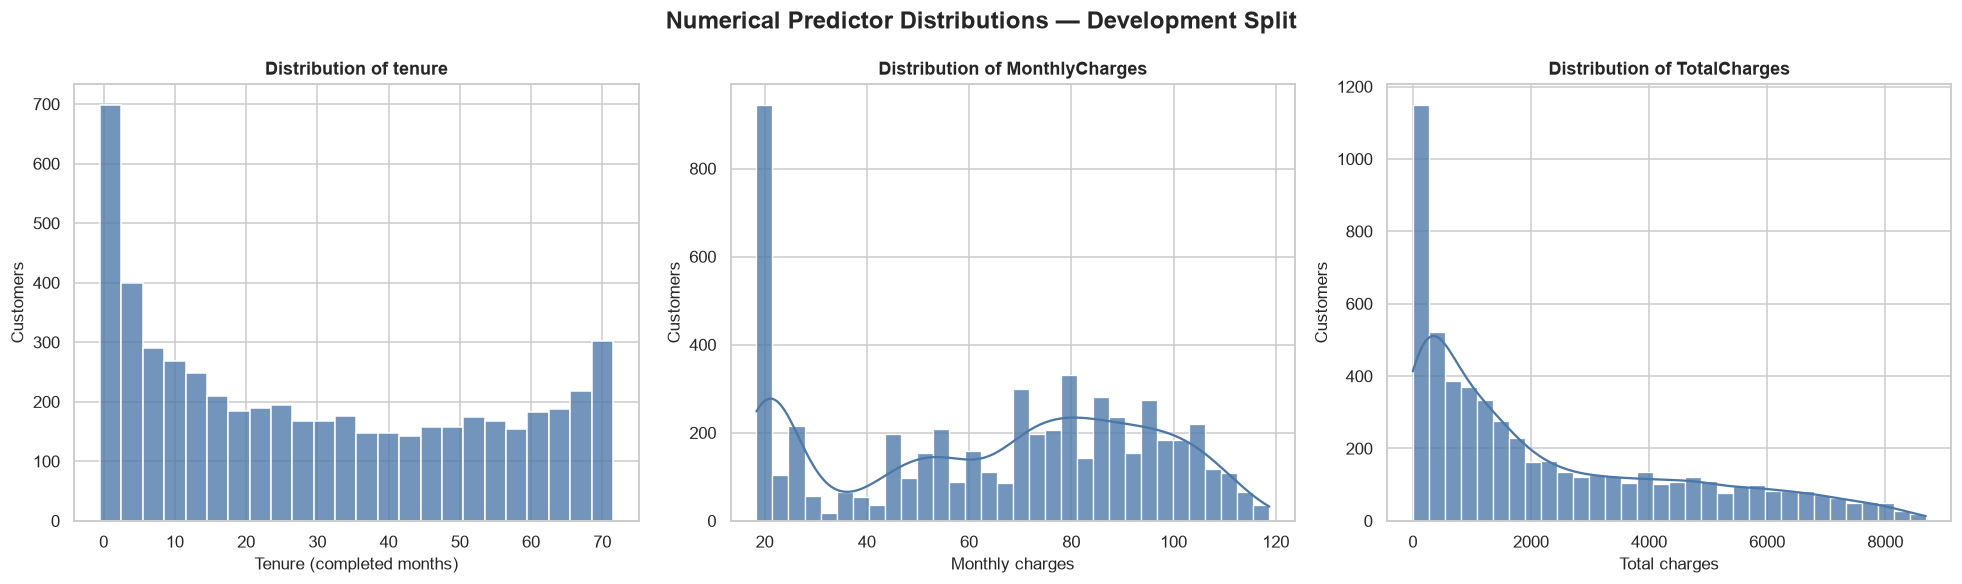

In [7]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
histogram_settings = {
    "tenure": {
        "bins": np.arange(-0.5, 73.5, 3),
        "kde": False,
        "xlabel": "Tenure (completed months)",
    },
    "MonthlyCharges": {"bins": 32, "kde": True, "xlabel": "Monthly charges"},
    "TotalCharges": {"bins": 32, "kde": True, "xlabel": "Total charges"},
}

for axis, column in zip(axes, numerical_features, strict=True):
    settings = histogram_settings[column]
    sns.histplot(
        data=df,
        x=column,
        bins=settings["bins"],
        kde=settings["kde"],
        color="#4C78A8",
        edgecolor="white",
        alpha=0.78,
        ax=axis,
    )
    axis.set(
        title=f"Distribution of {column}",
        xlabel=settings["xlabel"],
        ylabel="Customers",
    )

fig.suptitle(
    "Numerical Predictor Distributions — Development Split",
    fontsize=16,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

**Observed interpretation.** Tenure has a U-like/end-concentrated profile rather than a
normal bell shape. Monthly charges contain a pronounced low-price cluster and a broad
higher-price concentration, consistent with the exploratory KDE peaks. Total charges have
many low accumulated values and a long upper tail. None of these shapes identifies churn
risk; they characterize the development population only.

## 4.2 Empirical cumulative distributions

The empirical cumulative distribution function is

$$\widehat F_n(x)=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}(x_i\le x).$$

It answers “what fraction of observations are at or below $x$?” without histogram bins or
KDE bandwidth. Flat regions indicate few observations; steep sections indicate
concentration. Steps are natural for discrete tenure. ECDFs do not directly show local
density as intuitively as histograms.

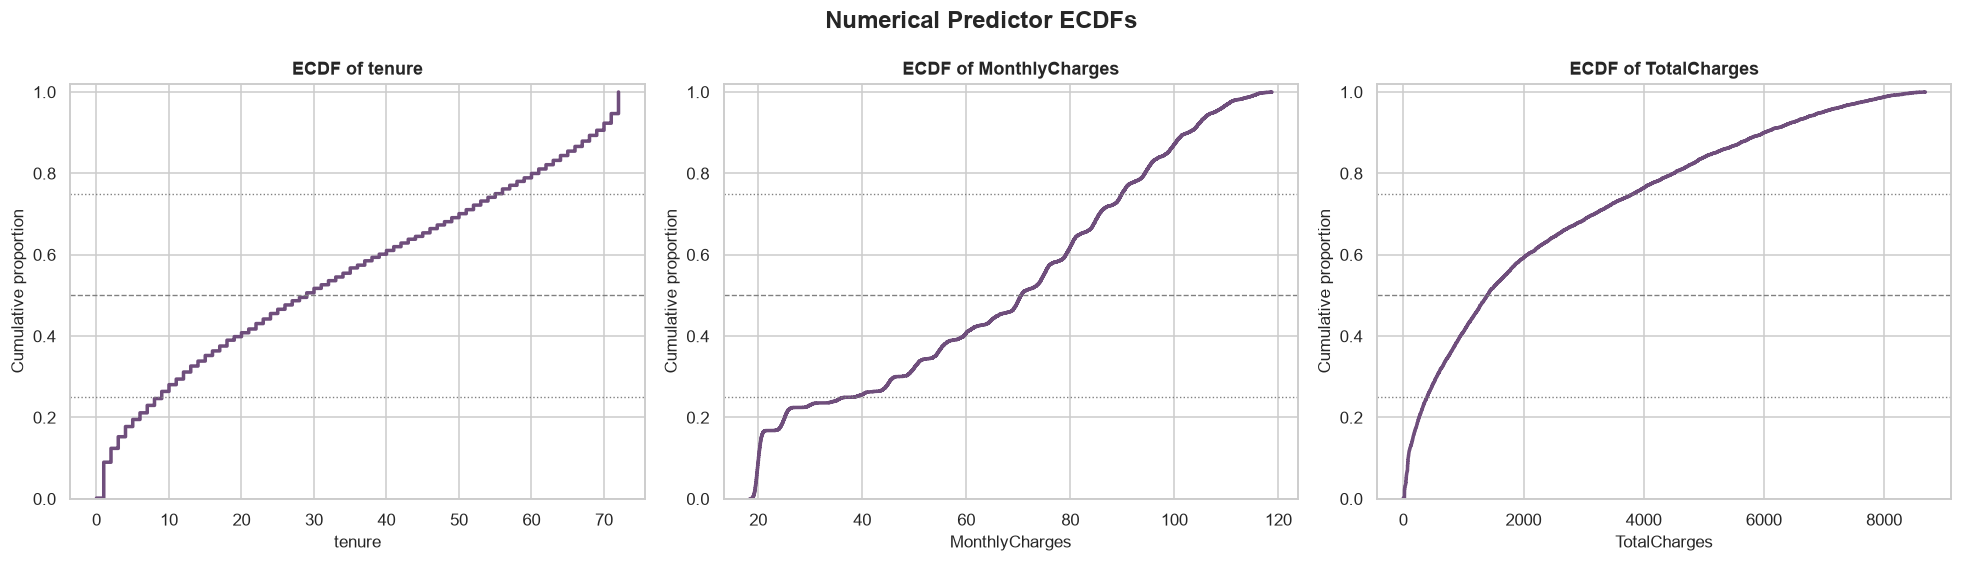

In [8]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for axis, column in zip(axes, numerical_features, strict=True):
    sns.ecdfplot(data=df, x=column, linewidth=2.3, color="#6F4E7C", ax=axis)
    for probability, linestyle in [(0.25, ":"), (0.50, "--"), (0.75, ":")]:
        axis.axhline(probability, color="grey", linestyle=linestyle, linewidth=0.9)
    axis.set(
        title=f"ECDF of {column}",
        xlabel=column,
        ylabel="Cumulative proportion",
        ylim=(0, 1.02),
    )
fig.suptitle("Numerical Predictor ECDFs", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

## 4.3 Box and violin plots

A box plot summarizes $Q_1$, median, $Q_3$, and conventional $1.5\times IQR$ whiskers.
Values beyond whiskers are review candidates—not automatically errors. A violin plot
mirrors a KDE around an axis, showing smoothed density plus quartile markers.

Box plots are compact but hide multimodality and sample concentration. Violin plots reveal
shape but inherit KDE bandwidth limitations and are especially approximate for discrete
tenure. Separate axes are used because the three variables have different units and
ranges; visual width should not be compared across panels.

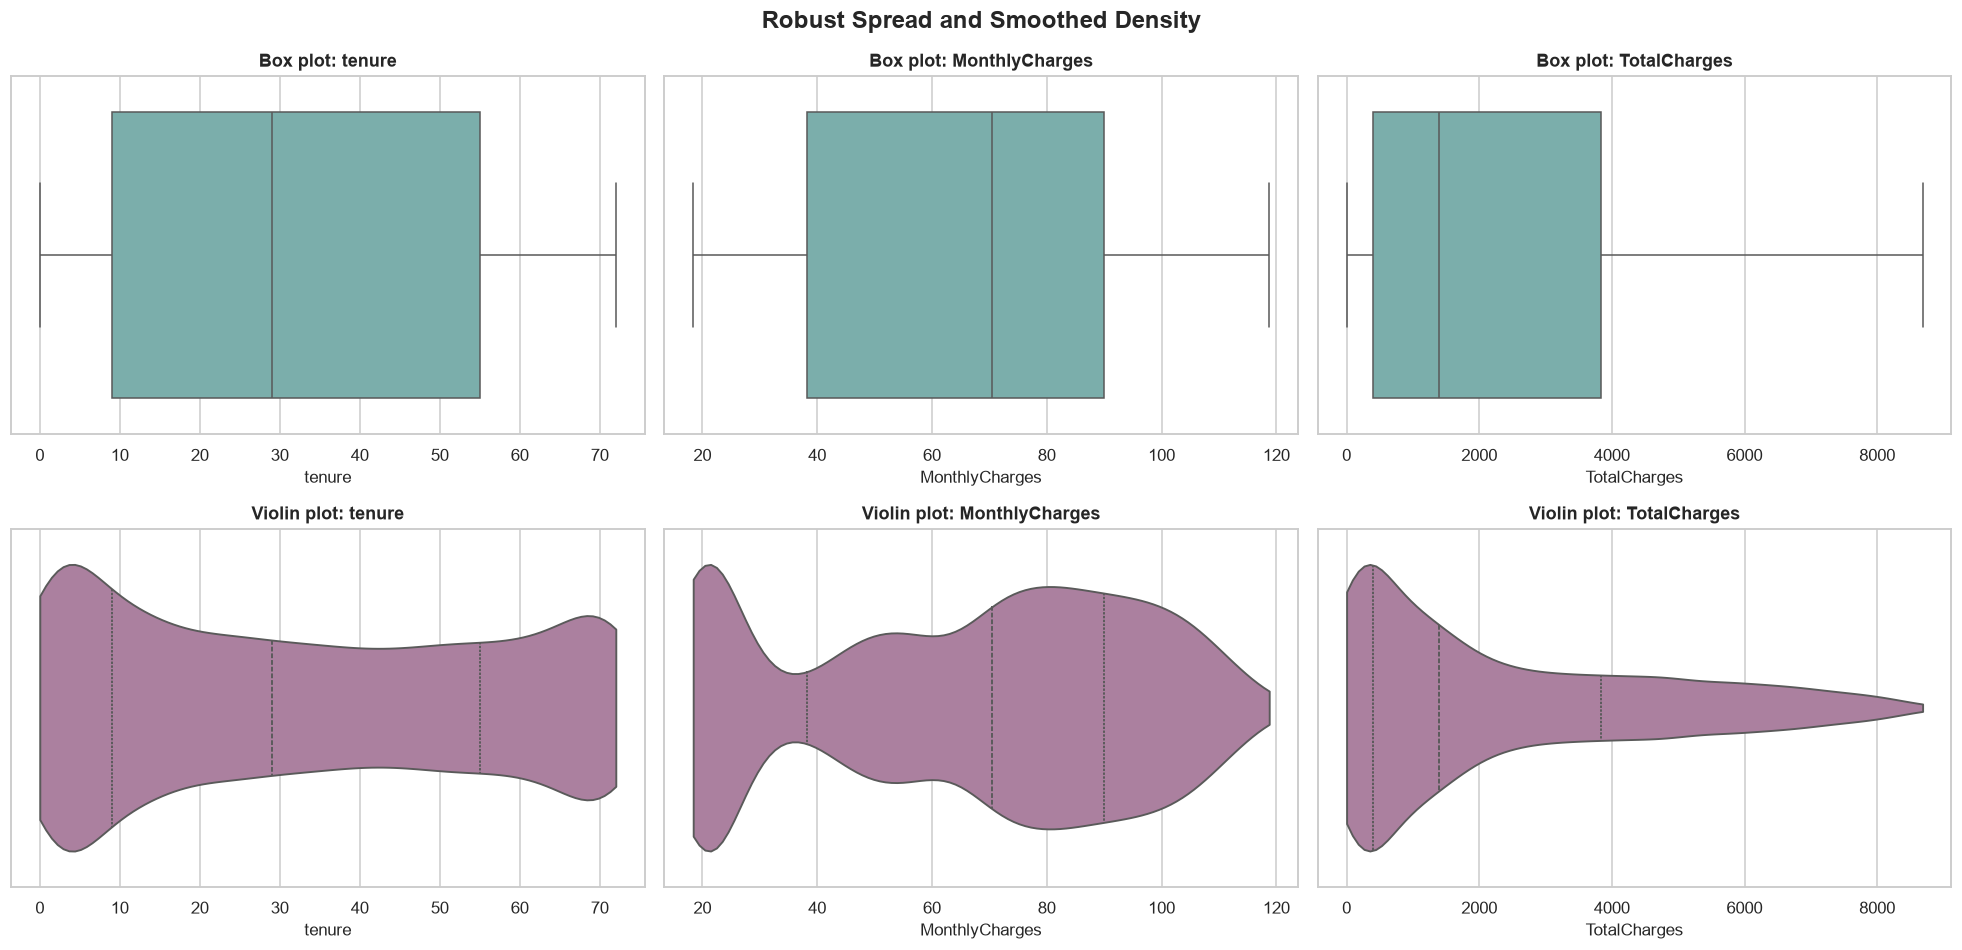

In [9]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 3, figsize=(18, 8.8))
for column, box_axis, violin_axis in zip(
    numerical_features,
    axes[0],
    axes[1],
    strict=True,
):
    sns.boxplot(data=df, x=column, color="#72B7B2", ax=box_axis)
    box_axis.set(title=f"Box plot: {column}", xlabel=column)
    sns.violinplot(
        data=df,
        x=column,
        color="#B279A2",
        inner="quartile",
        cut=0,
        ax=violin_axis,
    )
    violin_axis.set(title=f"Violin plot: {column}", xlabel=column)

fig.suptitle(
    "Robust Spread and Smoothed Density",
    fontsize=16,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 4.4 Quantile profiles

Quantiles summarize distribution position without assuming normality. $Q(p)$ is a value
at or below which approximately proportion $p$ of observations fall. Plotting quantiles
against their cumulative probabilities shows how rapidly a variable changes across the
population. A steep upper segment indicates a stretched upper tail; repeated quantiles
indicate ties or a boundary concentration.

Quantile profiles suppress local modes and do not identify individual outliers, so they
complement rather than replace density and box plots.

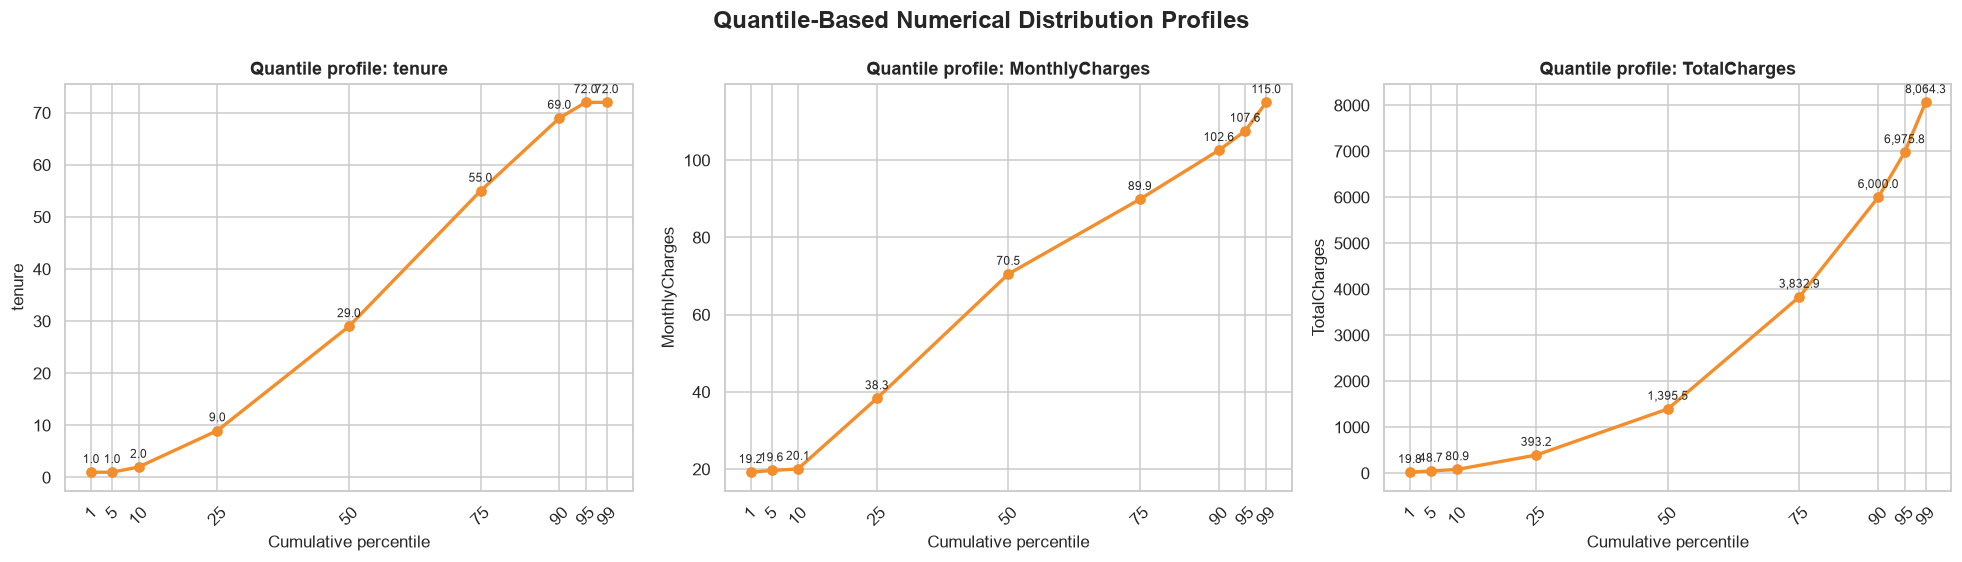

In [10]:
# ruff: noqa: E501
quantile_probabilities = np.array([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
quantile_profile = (
    df[numerical_features]
    .quantile(quantile_probabilities)
    .rename_axis("quantile")
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for axis, column in zip(axes, numerical_features, strict=True):
    axis.plot(
        quantile_probabilities * 100,
        quantile_profile[column],
        marker="o",
        linewidth=2.2,
        color="#F28E2B",
    )
    for probability, value in quantile_profile[column].items():
        axis.annotate(
            f"{value:,.1f}",
            (probability * 100, value),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
    axis.set(
        title=f"Quantile profile: {column}",
        xlabel="Cumulative percentile",
        ylabel=column,
        xticks=quantile_probabilities * 100,
    )
    axis.tick_params(axis="x", rotation=45)

fig.suptitle("Quantile-Based Numerical Distribution Profiles", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

# 5. Categorical predictor profiling

For category $c$ of feature $X$,

$$p_c=\frac{n_c}{n},\qquad \text{percentage}_c=100p_c.$$

Cardinality is the observed number of categories. The dominant and least frequent
categories reveal imbalance within a predictor. The consolidated table includes the
number of categories and observations below the exploratory 1% rarity threshold.

Category labels are structural states, not ordered numbers. In particular,
`SeniorCitizen=0/1` is categorical, and `No internet service` / `No phone service` are
valid service states rather than encoded missing values.

In [11]:
# ruff: noqa: E501
rare_threshold = 0.01
categorical_profile_rows = []
categorical_frequency_rows = []

for column in categorical_features:
    counts = df[column].value_counts(dropna=False)
    percentages = counts / len(df) * 100
    rare_mask = percentages.lt(rare_threshold * 100)

    categorical_profile_rows.append({
        "feature": column,
        "unique_categories": len(counts),
        "most_frequent_category": str(counts.index[0]),
        "most_frequent_count": int(counts.iloc[0]),
        "dominant_category_percentage": percentages.iloc[0],
        "least_frequent_category": str(counts.index[-1]),
        "least_frequent_count": int(counts.iloc[-1]),
        "least_frequent_percentage": percentages.iloc[-1],
        "rare_category_count_below_1_percent": int(rare_mask.sum()),
        "rare_observation_count": int(counts.loc[rare_mask].sum()),
        "rare_observation_percentage": percentages.loc[rare_mask].sum(),
    })

    for category, count in counts.items():
        categorical_frequency_rows.append({
            "feature": column,
            "category": str(category),
            "count": int(count),
            "percentage": count / len(df) * 100,
            "below_1_percent": count / len(df) < rare_threshold,
        })

categorical_profile = pd.DataFrame(categorical_profile_rows).set_index("feature")
categorical_frequencies = pd.DataFrame(categorical_frequency_rows)

display(categorical_profile)
display(Markdown("**Complete category frequency and percentage table**"))
display(categorical_frequencies)

,unique_categories,most_frequent_category,most_frequent_count,dominant_category_percentage,least_frequent_category,least_frequent_count,least_frequent_percentage,rare_category_count_below_1_percent,rare_observation_count,rare_observation_percentage
feature,,,,,,,,,,
gender,2,Male,2862,50.799,Female,2772,49.201,0,0,0.000
SeniorCitizen,2,0,4726,83.884,1,908,16.116,0,0,0.000
Partner,2,No,2936,52.112,Yes,2698,47.888,0,0,0.000
Dependents,2,No,3924,69.649,Yes,1710,30.351,0,0,0.000
PhoneService,2,Yes,5105,90.611,No,529,9.389,0,0,0.000
PaperlessBilling,2,Yes,3365,59.727,No,2269,40.273,0,0,0.000
Contract,3,Month-to-month,3095,54.934,One year,1178,20.909,0,0,0.000
MultipleLines,3,No,2730,48.456,No phone service,529,9.389,0,0,0.000
InternetService,3,Fiber optic,2493,44.249,No,1207,21.424,0,0,0.000


**Complete category frequency and percentage table**

,feature,category,count,percentage,below_1_percent
0,gender,Male,2862,50.799,False
1,gender,Female,2772,49.201,False
2,SeniorCitizen,0,4726,83.884,False
3,SeniorCitizen,1,908,16.116,False
4,Partner,No,2936,52.112,False
5,Partner,Yes,2698,47.888,False
6,Dependents,No,3924,69.649,False
7,Dependents,Yes,1710,30.351,False
8,PhoneService,Yes,5105,90.611,False
9,PhoneService,No,529,9.389,False


## 5.1 Business-dimension category visualizations

Percentage bars are grouped by telecom meaning rather than column order. This makes
adoption patterns easier to interpret without combining unrelated categories. Each panel
sums to 100% for its own feature, so bar heights should be compared within a panel—not as
joint probabilities across panels.

The charts remain univariate. For example, a large month-to-month group does not establish
that contract type is related to churn; that question belongs to later bivariate analysis.

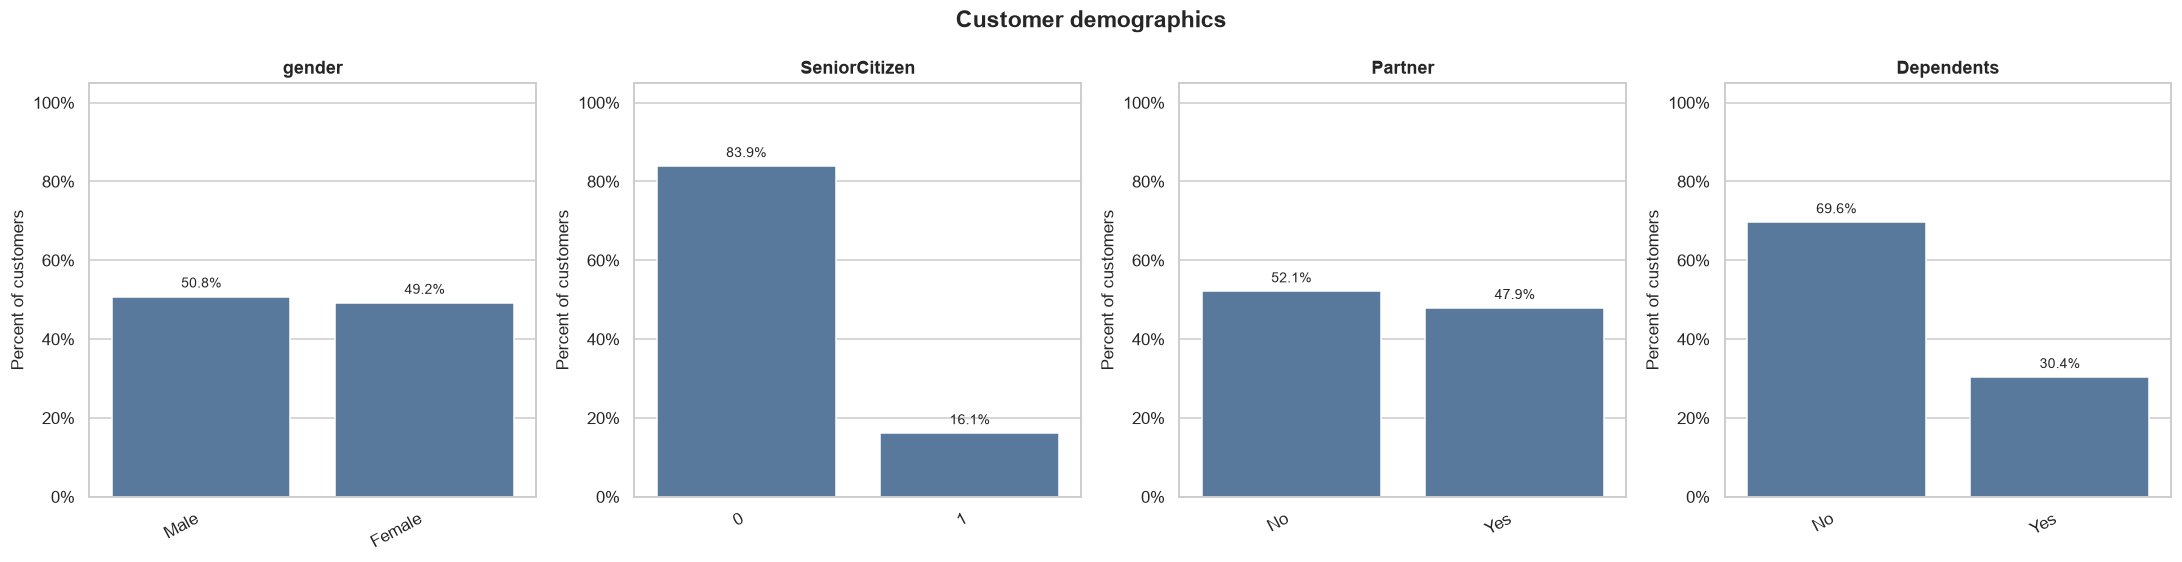

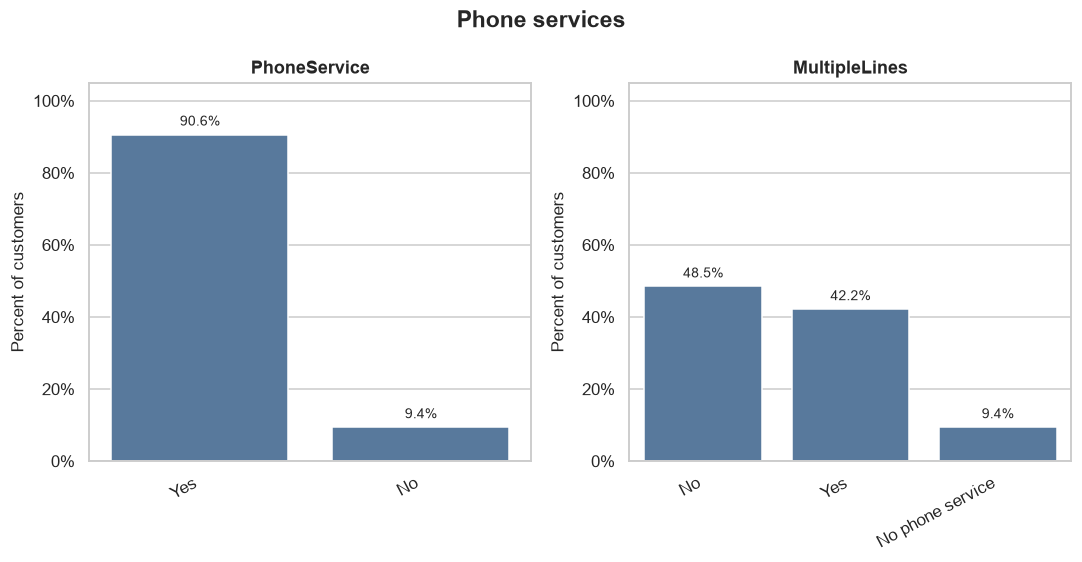

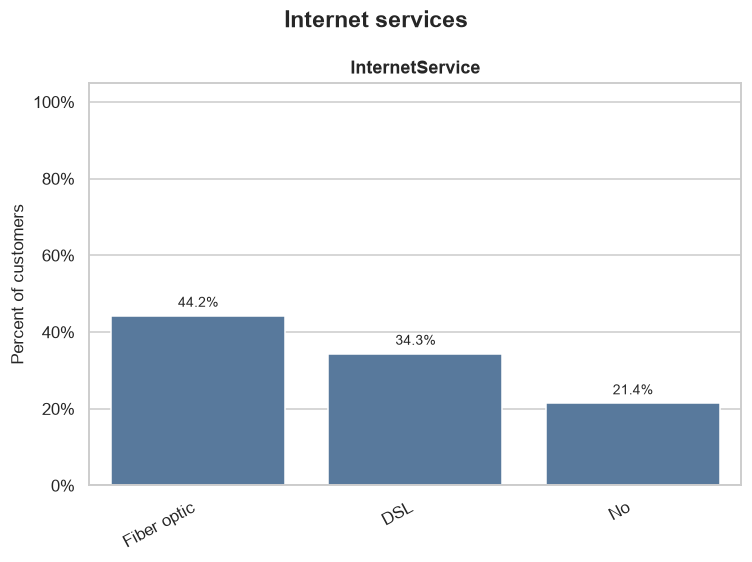

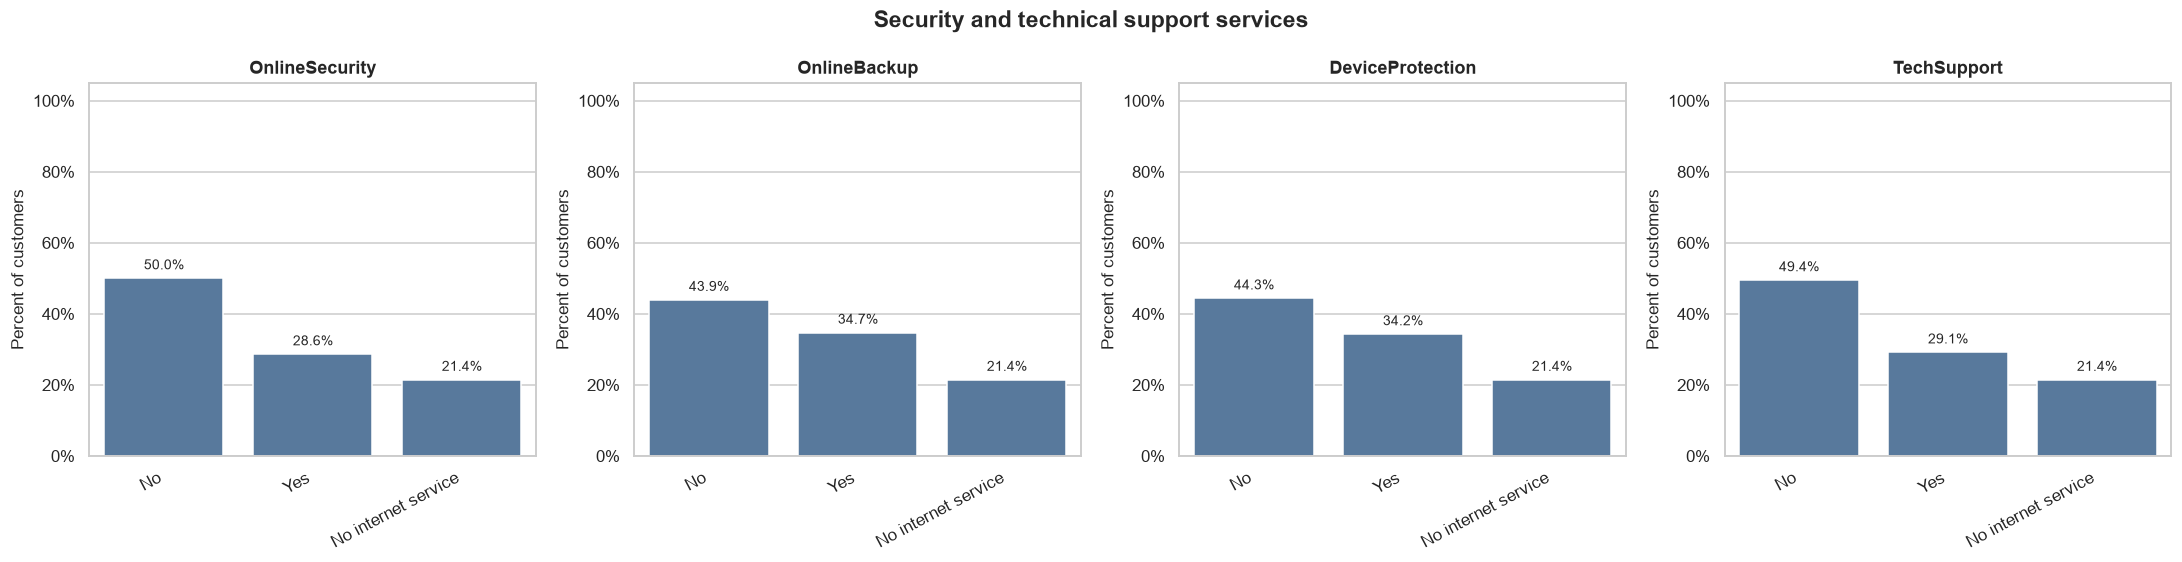

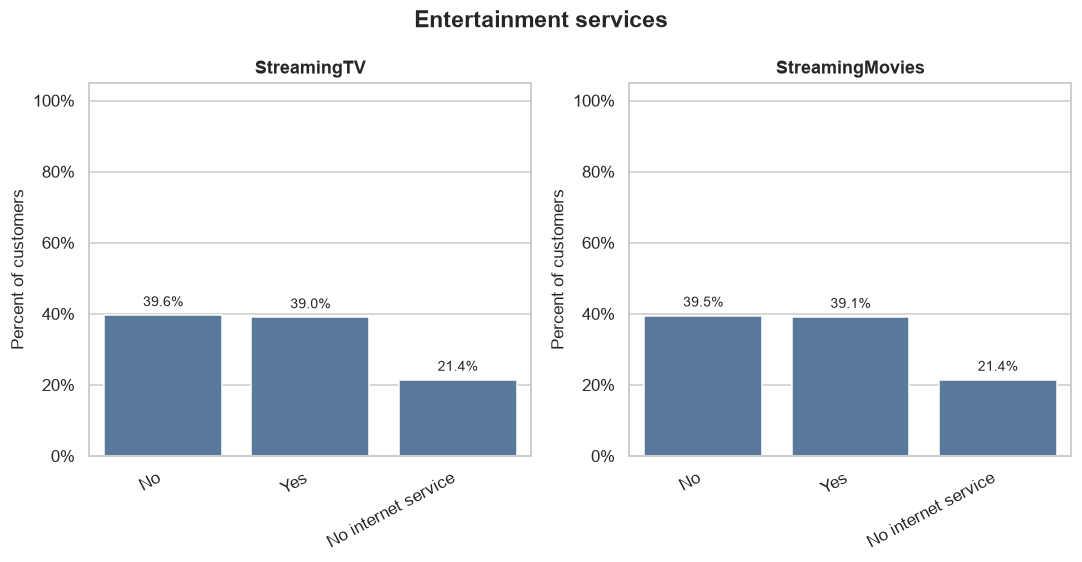

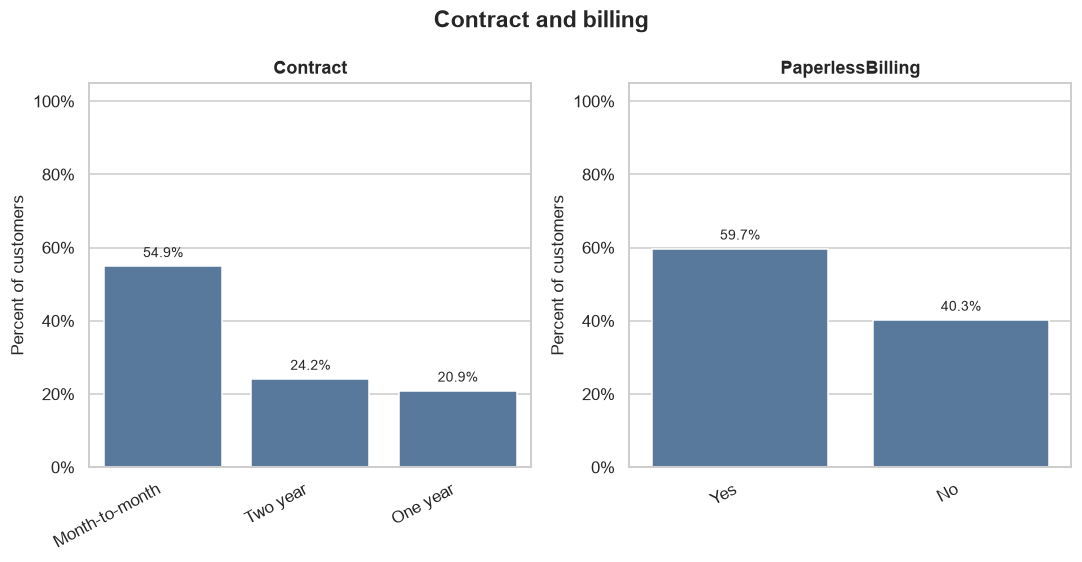

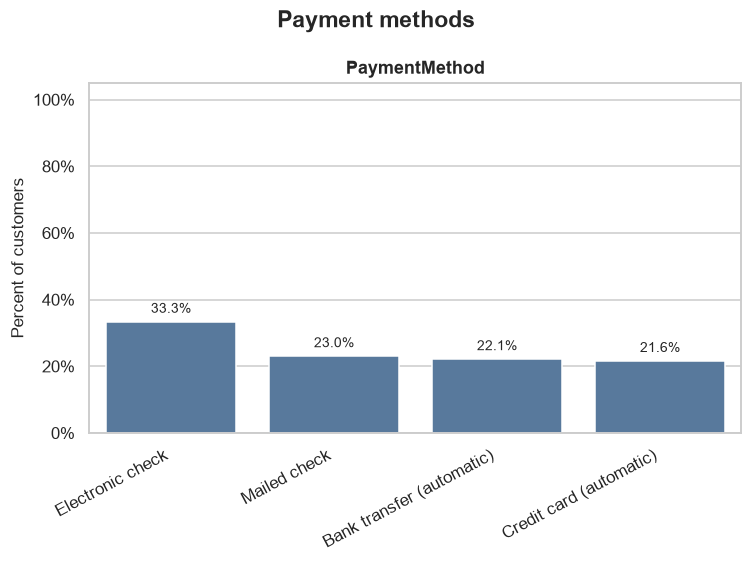

In [12]:
# ruff: noqa: E501
business_dimensions = {
    "Customer demographics": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "Phone services": ["PhoneService", "MultipleLines"],
    "Internet services": ["InternetService"],
    "Security and technical support services": [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
    ],
    "Entertainment services": ["StreamingTV", "StreamingMovies"],
    "Contract and billing": ["Contract", "PaperlessBilling"],
    "Payment methods": ["PaymentMethod"],
}

category_color = "#4C78A8"
for dimension, features in business_dimensions.items():
    figure_width = max(7, 5.0 * len(features))
    fig, axes = plt.subplots(1, len(features), figsize=(figure_width, 5.2), squeeze=False)
    for axis, column in zip(axes.flat, features, strict=True):
        percentages = df[column].astype(str).value_counts(normalize=True).mul(100)
        sns.barplot(
            x=percentages.index,
            y=percentages.values,
            color=category_color,
            ax=axis,
        )
        axis.set(
            title=column,
            xlabel="",
            ylabel="Percent of customers",
            ylim=(0, 105),
        )
        axis.yaxis.set_major_formatter(PercentFormatter(xmax=100))
        axis.tick_params(axis="x", rotation=28)
        for label in axis.get_xticklabels():
            label.set_horizontalalignment("right")
        for patch, value in zip(axis.patches, percentages.values, strict=True):
            axis.annotate(
                f"{value:.1f}%",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center",
                va="bottom",
                fontsize=9,
                xytext=(0, 4),
                textcoords="offset points",
            )
    fig.suptitle(dimension, fontsize=15, fontweight="bold")
    fig.tight_layout()
    plt.show()

## 5.2 Structural service states

`No internet service` means an add-on is not applicable because the customer has no
internet subscription. It must not be collapsed into ordinary `No`, which means the
customer has internet access but not that add-on. Similarly, `No phone service` is distinct
from declining multiple lines while having phone service.

The consistency checks below compare these structural labels with their parent service
states. This validates interpretation without transforming categories.

In [13]:
# ruff: noqa: E501
internet_addon_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]
no_internet_count = int(df["InternetService"].eq("No").sum())
structural_state_rows = []
for column in internet_addon_features:
    count = int(df[column].eq("No internet service").sum())
    structural_state_rows.append({
        "feature": column,
        "structural_category": "No internet service",
        "count": count,
        "parent_service_absent_count": no_internet_count,
        "counts_match": count == no_internet_count,
    })

no_phone_count = int(df["PhoneService"].eq("No").sum())
multiple_lines_no_phone_count = int(df["MultipleLines"].eq("No phone service").sum())
structural_state_rows.append({
    "feature": "MultipleLines",
    "structural_category": "No phone service",
    "count": multiple_lines_no_phone_count,
    "parent_service_absent_count": no_phone_count,
    "counts_match": multiple_lines_no_phone_count == no_phone_count,
})

structural_state_summary = pd.DataFrame(structural_state_rows)
assert structural_state_summary["counts_match"].all()
display(structural_state_summary)
display(Markdown(
    f"**Observed result:** all six internet add-ons contain exactly {no_internet_count:,} "
    "`No internet service` records, matching the parent service state. `MultipleLines` contains "
    f"{no_phone_count:,} `No phone service` records, also matching its parent state. These are "
    "complete, internally consistent structural categories—not nulls."
))

,feature,structural_category,count,parent_service_absent_count,counts_match
0,OnlineSecurity,No internet service,1207,1207,True
1,OnlineBackup,No internet service,1207,1207,True
2,DeviceProtection,No internet service,1207,1207,True
3,TechSupport,No internet service,1207,1207,True
4,StreamingTV,No internet service,1207,1207,True
5,StreamingMovies,No internet service,1207,1207,True
6,MultipleLines,No phone service,529,529,True


**Observed result:** all six internet add-ons contain exactly 1,207 `No internet service` records, matching the parent service state. `MultipleLines` contains 529 `No phone service` records, also matching its parent state. These are complete, internally consistent structural categories—not nulls.

# 6. Rare category analysis

An exploratory category is labelled rare when

$$\frac{n_c}{n}<0.01.$$

The 1% threshold is a documented screening convention, not a universal rule. Rare
categories can produce unstable model coefficients, high-variance estimates, or validation
folds with very few examples. A non-stratified split with respect to that predictor can
even omit a rare level from a fold, causing encoder or scoring problems.

Rare categories should not be removed automatically: they may represent important
customers, legally protected groups, high-value services, data-quality signals, or
operational edge cases. Later feature engineering could group semantically compatible rare
levels, use encoders that handle unseen values, apply partial pooling/regularization, or
collect more data. Those actions require domain review and cross-validated evidence; none
is performed here.

In [14]:
# ruff: noqa: E501
rare_categories = categorical_frequencies.loc[
    categorical_frequencies["below_1_percent"]
].copy()

if rare_categories.empty:
    display(Markdown(
        "**Observed result:** no category in any categorical predictor falls below the "
        "exploratory 1% threshold. The smallest observed category is `No` phone service / "
        "`No phone service`, with 529 customers (9.39%). This does not guarantee that future "
        "production batches or cross-validation subgroups will have the same support."
    ))
else:
    display(rare_categories)

rare_category_summary = pd.DataFrame([{
    "threshold_percentage": rare_threshold * 100,
    "categorical_predictors_examined": len(categorical_features),
    "categories_examined": len(categorical_frequencies),
    "rare_categories_found": len(rare_categories),
    "rare_observations_found": int(rare_categories["count"].sum()),
}])
display(rare_category_summary)

**Observed result:** no category in any categorical predictor falls below the exploratory 1% threshold. The smallest observed category is `No` phone service / `No phone service`, with 529 customers (9.39%). This does not guarantee that future production batches or cross-validation subgroups will have the same support.

,threshold_percentage,categorical_predictors_examined,categories_examined,rare_categories_found,rare_observations_found
0,1.000,16,43,0,0


# 7. Constant and near-constant feature analysis

A constant feature has one observed value or zero numerical variance. For this exploratory
screen, a feature is **near-constant** when one exact value/category represents at least
95% of observations:

$$\max_c p_c\ge0.95.$$

Low variability can reduce information available to a model, create unstable estimates,
or add computational burden. It does not prove low predictive usefulness: a small group
may be highly informative, and numeric variables can have useful ordering even when many
values repeat. The threshold is a review flag, not a removal rule.

In [15]:
# ruff: noqa: E501
dominance_threshold = 0.95
variability_rows = []

for column in categorical_features:
    proportions = df[column].value_counts(normalize=True, dropna=False)
    variability_rows.append({
        "feature": column,
        "feature_type": "Categorical",
        "unique_values": df[column].nunique(dropna=False),
        "variance": np.nan,
        "dominant_exact_value": str(proportions.index[0]),
        "dominant_percentage": proportions.iloc[0] * 100,
        "constant": len(proportions) == 1,
        "near_constant_at_95_percent": proportions.iloc[0] >= dominance_threshold,
    })

for column in numerical_features:
    proportions = df[column].value_counts(normalize=True, dropna=False)
    variance = df[column].var(ddof=0)
    variability_rows.append({
        "feature": column,
        "feature_type": "Numerical",
        "unique_values": df[column].nunique(dropna=False),
        "variance": variance,
        "dominant_exact_value": str(proportions.index[0]),
        "dominant_percentage": proportions.iloc[0] * 100,
        "constant": variance == 0,
        "near_constant_at_95_percent": proportions.iloc[0] >= dominance_threshold,
    })

variability_profile = pd.DataFrame(variability_rows).set_index("feature")
display(variability_profile.sort_values("dominant_percentage", ascending=False))

constant_features = variability_profile.index[variability_profile["constant"]].tolist()
near_constant_features = variability_profile.index[
    variability_profile["near_constant_at_95_percent"]
].tolist()
zero_variance_numerical_features = variability_profile.index[
    variability_profile["feature_type"].eq("Numerical")
    & variability_profile["variance"].eq(0)
].tolist()

display(Markdown(
    f"**Observed result:** constant predictors: `{constant_features or 'none'}`; "
    f"near-constant predictors at 95%: `{near_constant_features or 'none'}`; "
    f"zero-variance numerical predictors: `{zero_variance_numerical_features or 'none'}`. "
    f"The most dominated predictor is `PhoneService`, whose `Yes` category contains "
    f"{categorical_profile.loc['PhoneService', 'dominant_category_percentage']:.2f}% of customers—"
    "highly uneven, but below the 95% review threshold."
))

,feature_type,unique_values,variance,dominant_exact_value,dominant_percentage,constant,near_constant_at_95_percent
feature,,,,,,,
PhoneService,Categorical,2,NaN,Yes,90.611,False,False
SeniorCitizen,Categorical,2,NaN,0,83.884,False,False
Dependents,Categorical,2,NaN,No,69.649,False,False
PaperlessBilling,Categorical,2,NaN,Yes,59.727,False,False
Contract,Categorical,3,NaN,Month-to-month,54.934,False,False
Partner,Categorical,2,NaN,No,52.112,False,False
gender,Categorical,2,NaN,Male,50.799,False,False
OnlineSecurity,Categorical,3,NaN,No,49.982,False,False
TechSupport,Categorical,3,NaN,No,49.450,False,False


**Observed result:** constant predictors: `none`; near-constant predictors at 95%: `none`; zero-variance numerical predictors: `none`. The most dominated predictor is `PhoneService`, whose `Yes` category contains 90.61% of customers—highly uneven, but below the 95% review threshold.

# 8. Shannon entropy analysis

For category probabilities $p_1,\ldots,p_K$, Shannon entropy in bits is

$$H(X)=-\sum_{i=1}^{K}p_i\log_2(p_i).$$

Entropy measures uncertainty or diversity in a feature's marginal category distribution.
It is zero for a constant feature and reaches its maximum $\log_2(K)$ when all $K$
categories are equally likely. Normalized entropy is

$$H_{norm}(X)=
\begin{cases}
H(X)/\log_2(K), & K>1,\\
0, & K=1.
\end{cases}$$

Raw entropy grows with both balance and cardinality, so it is not directly comparable
across different $K$. Normalized entropy lies from 0 to 1 and expresses balance relative
to the feature's own maximum.

High entropy does **not** imply predictive power: a perfectly balanced feature can be
independent of churn. Entropy describes one variable alone. **Information gain** is a
target-aware reduction in target entropy after observing a feature; it requires a joint
feature-target distribution and is intentionally deferred along with mutual information.

,observed_categories_K,shannon_entropy_bits,maximum_entropy_bits,normalized_entropy
feature,,,,
PhoneService,2,0.449,1.000,0.449
SeniorCitizen,2,0.637,1.000,0.637
MultipleLines,3,1.352,1.585,0.853
Dependents,2,0.886,1.000,0.886
Contract,3,1.442,1.585,0.910
OnlineSecurity,3,1.493,1.585,0.942
TechSupport,3,1.497,1.585,0.944
DeviceProtection,3,1.526,1.585,0.963
InternetService,3,1.526,1.585,0.963


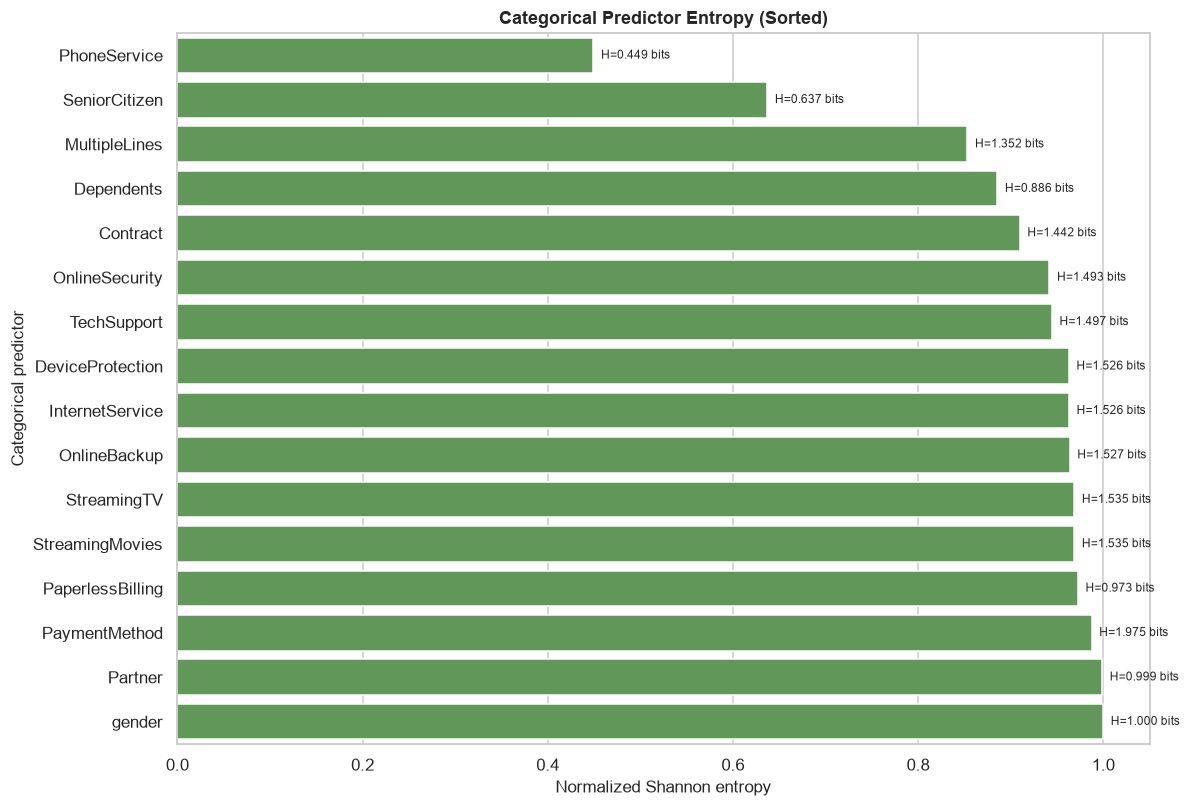

In [16]:
# ruff: noqa: E501
entropy_rows = []
for column in categorical_features:
    probabilities = df[column].value_counts(normalize=True, dropna=False).to_numpy()
    category_count = len(probabilities)
    raw_entropy = shannon_entropy(probabilities, base=2)
    maximum_entropy = np.log2(category_count) if category_count > 1 else 0.0
    normalized_entropy = (
        raw_entropy / maximum_entropy
        if maximum_entropy > 0
        else 0.0
    )
    entropy_rows.append({
        "feature": column,
        "observed_categories_K": category_count,
        "shannon_entropy_bits": raw_entropy,
        "maximum_entropy_bits": maximum_entropy,
        "normalized_entropy": normalized_entropy,
    })

entropy_profile = (
    pd.DataFrame(entropy_rows)
    .set_index("feature")
    .sort_values("normalized_entropy")
)
display(entropy_profile)

fig, axis = plt.subplots(figsize=(11, 7.5))
sns.barplot(
    data=entropy_profile.reset_index(),
    x="normalized_entropy",
    y="feature",
    color="#59A14F",
    ax=axis,
)
axis.set(
    title="Categorical Predictor Entropy (Sorted)",
    xlabel="Normalized Shannon entropy",
    ylabel="Categorical predictor",
    xlim=(0, 1.05),
)
for patch, (_, row) in zip(axis.patches, entropy_profile.iterrows(), strict=True):
    axis.annotate(
        f"H={row['shannon_entropy_bits']:.3f} bits",
        (patch.get_width(), patch.get_y() + patch.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )
plt.tight_layout()
plt.show()

In [17]:
# ruff: noqa: E501
lowest_entropy_feature = entropy_profile["normalized_entropy"].idxmin()
highest_entropy_feature = entropy_profile["normalized_entropy"].idxmax()
display(Markdown(
    "### Observed entropy findings\n\n"
    f"- `{lowest_entropy_feature}` has the lowest normalized entropy "
    f"({entropy_profile.loc[lowest_entropy_feature, 'normalized_entropy']:.3f}); its dominant category "
    f"contains {categorical_profile.loc[lowest_entropy_feature, 'dominant_category_percentage']:.2f}% "
    "of customers. It carries less marginal category uncertainty than the other predictors, but is not constant.\n"
    f"- `{highest_entropy_feature}` has the highest normalized entropy "
    f"({entropy_profile.loc[highest_entropy_feature, 'normalized_entropy']:.3f}). Its categories are close to "
    "evenly distributed relative to its cardinality.\n"
    f"- `PaymentMethod` has the highest raw entropy at "
    f"{entropy_profile.loc['PaymentMethod', 'shannon_entropy_bits']:.3f} bits because it has four fairly "
    "balanced categories. Raw entropy should not be compared to binary entropy without considering K.\n"
    "- These are feature-only information-content results. They do not rank predictors for churn modelling."
))

### Observed entropy findings

- `PhoneService` has the lowest normalized entropy (0.449); its dominant category contains 90.61% of customers. It carries less marginal category uncertainty than the other predictors, but is not constant.
- `gender` has the highest normalized entropy (1.000). Its categories are close to evenly distributed relative to its cardinality.
- `PaymentMethod` has the highest raw entropy at 1.975 bits because it has four fairly balanced categories. Raw entropy should not be compared to binary entropy without considering K.
- These are feature-only information-content results. They do not rank predictors for churn modelling.

# 9. Business interpretation and next questions

## Observed population patterns

- **Customer lifecycle:** tenure is concentrated at 1 month and again at the 72-month
  ceiling. The middle 50% spans 9–55 months. Lifecycle-specific experiences may be worth
  investigating later, but marginal tenure alone says nothing about churn.
- **Subscription prices:** monthly charges show a low-price cluster and a broad
  higher-price cluster, with exploratory KDE peaks near 21 and 81 units. This may reflect
  product bundles or service tiers and should be tested against service adoption later.
- **Accumulated expenditure:** total charges are strongly right-skewed and highly
  dispersed (CV about 99%). The pattern is compatible with cumulative billing over
  different tenures and prices, but that relationship is not analysed here.
- **Service adoption:** 90.61% have phone service; 44.25% use fibre optic, 34.33% DSL, and
  21.42% have no internet service. Structural no-service states are internally consistent
  and must remain distinct from ordinary `No`.
- **Support and entertainment:** internet add-on categories are reasonably populated.
  `No` is the largest state for security and technical support, while streaming `Yes` and
  `No` shares are close among the full population once the no-internet group is included.
- **Contracts and billing:** 54.93% are month-to-month and 59.73% use paperless billing.
- **Payment behaviour:** electronic check is largest at 33.32%; the four methods are
  relatively balanced, producing high normalized entropy.
- **Rarity and dominance:** no category is below 1%, and no predictor is constant or
  dominated at 95%. Phone service is the most uneven predictor at 90.61% `Yes`.

These patterns inform data preparation and business questions, but none establishes a
feature's relationship with churn.

## Questions for subsequent bivariate analysis

1. Do the low- and high-price monthly-charge concentrations correspond to internet type,
   add-on adoption, or phone configuration?
2. How does contract type vary across tenure ranges, without yet interpreting causality?
3. Are paperless billing and payment-method distributions associated with service bundles?
4. How do structural no-service categories affect apparent category comparisons?
5. Which predictors show practically meaningful churn-rate differences with adequate group
   support and uncertainty estimates?
6. Does accumulated expenditure behave consistently with tenure and monthly charges, or
   are there billing combinations requiring quality review?

# 10. Interview questions with speakable answers

### 1. Why can a feature with high Shannon entropy still be useless for prediction?

**Speakable answer:** “Entropy measures uncertainty in the feature's own marginal
distribution. A balanced category mix gives high entropy, but it may be completely
independent of the target. Predictive information requires a joint measure such as
information gain or mutual information, evaluated without leakage. In this step I use
entropy only to understand category diversity.”

### 2. How would you discuss the two KDE peaks in monthly charges?

**Speakable answer:** “The selected bandwidth and prominence rule finds peaks near 21 and
81 units, so the sample may contain multiple price concentrations. I would call this
exploratory evidence, not proof of two latent populations, because KDE modes depend on
bandwidth and boundaries. I would next compare price with service bundles and plan states,
while keeping target analysis separate.”

### 3. Why not merge `No internet service` with `No`?

**Speakable answer:** “They encode different business states. `No` means the customer has
internet but did not adopt the add-on; `No internet service` means the add-on is not
applicable. Collapsing them destroys information and may create misleading service-adoption
comparisons. The development data also show the structural count matches the parent
no-internet count exactly.”

### 4. Should a 95%-dominant or sub-1% category be removed automatically?

**Speakable answer:** “No. Those thresholds are screening rules. A rare group may be
important or highly informative, while a dominant feature may still separate a critical
minority. I would examine data quality, semantics, fold stability, regularization, unseen-
category handling, and out-of-fold performance before considering grouping or removal.
Feature selection belongs to a later validated pipeline.”

# 11. Verification, limitations, and leakage audit

## Remaining limitations

- This is a static development sample, not a time-indexed production population.
- KDE peaks and rarity/dominance thresholds depend on documented exploratory choices.
- Exact category support may change across future or smaller samples.
- Currency and detailed product-plan metadata are not documented.
- No formal normality, modality, or hypothesis test is performed.
- No association with `Churn`, predictive usefulness, causality, fairness, or intervention
  effect is assessed.

The following assertions verify source scope, row preservation, predictor separation, and
the absence of analysis-time data modification.

In [18]:
# ruff: noqa: E501
assert development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
assert len(df) == 5_634
assert df.shape[1] == 21
assert df[target_column].notna().all()
assert target_column not in predictor_columns
assert identifier_column not in predictor_columns
assert not rare_categories.shape[0]
assert not constant_features
assert not near_constant_features
assert not zero_variance_numerical_features

print("Leakage audit passed: exactly one configured development Parquet input was loaded.")
print("Target and customer identifier were excluded from all predictor profiles.")
print("No rows, categories, outliers, or predictors were transformed or removed.")
print("No bivariate, target-association, inferential, balancing, or modelling step was run.")

Leakage audit passed: exactly one configured development Parquet input was loaded.
Target and customer identifier were excluded from all predictor profiles.
No rows, categories, outliers, or predictors were transformed or removed.
No bivariate, target-association, inferential, balancing, or modelling step was run.
